# Brazilian E-Commerce (Olist) — EDA & Data Cleaning
**Dataset:** 100K+ orders from 2016–2018  
**Goal:** Understand what drives customer satisfaction and repeat purchases

## 1. Setup & Load Data

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

DATA_PATH = 'data/'

orders       = pd.read_csv(DATA_PATH + 'olist_orders_dataset.csv')
customers    = pd.read_csv(DATA_PATH + 'olist_customers_dataset.csv')
order_items  = pd.read_csv(DATA_PATH + 'olist_order_items_dataset.csv')
payments     = pd.read_csv(DATA_PATH + 'olist_order_payments_dataset.csv')
reviews      = pd.read_csv(DATA_PATH + 'olist_order_reviews_dataset.csv')
products     = pd.read_csv(DATA_PATH + 'olist_products_dataset.csv')
sellers      = pd.read_csv(DATA_PATH + 'olist_sellers_dataset.csv')
geolocation  = pd.read_csv(DATA_PATH + 'olist_geolocation_dataset.csv')
translations = pd.read_csv(DATA_PATH + 'product_category_name_translation.csv')

print('All files loaded successfully')

All files loaded successfully


## 2. EDA — Shape & Schema Overview

In [31]:
datasets = {
    'orders': orders,
    'customers': customers,
    'order_items': order_items,
    'payments': payments,
    'reviews': reviews,
    'products': products,
    'sellers': sellers,
    'geolocation': geolocation,
    'translations': translations
}

## 3. EDA — Missing Values

In [32]:
print('=== ORDERS ===')
print(orders.isnull().sum()[orders.isnull().sum() > 0])

print('\n=== REVIEWS ===')
print(reviews.isnull().sum()[reviews.isnull().sum() > 0])

print('\n=== PRODUCTS ===')
print(products.isnull().sum()[products.isnull().sum() > 0])

print('\n=== ORDER ITEMS ===')
print(order_items.isnull().sum()[order_items.isnull().sum() > 0])

=== ORDERS ===
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

=== REVIEWS ===
review_comment_title      87656
review_comment_message    58247
dtype: int64

=== PRODUCTS ===
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

=== ORDER ITEMS ===
Series([], dtype: int64)


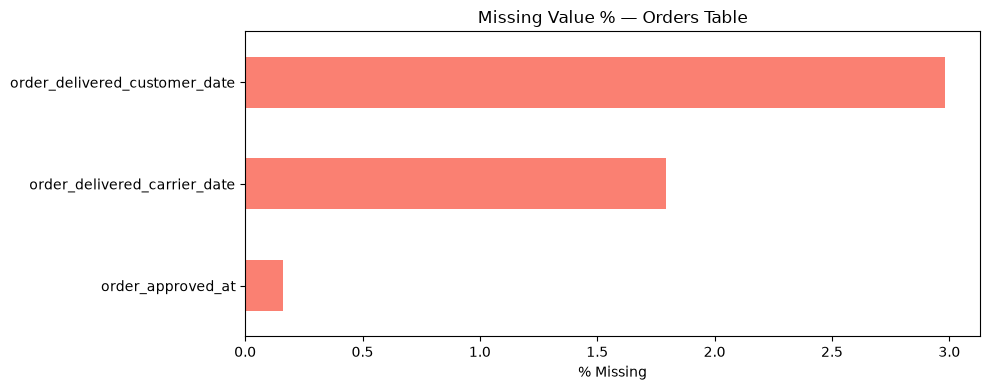

In [33]:
# Visualise missing values across orders
fig, ax = plt.subplots(figsize=(10, 4))
null_pct = orders.isnull().mean() * 100
null_pct[null_pct > 0].sort_values().plot(kind='barh', ax=ax, color='salmon')
ax.set_title('Missing Value % — Orders Table')
ax.set_xlabel('% Missing')
plt.tight_layout()
plt.show()

## 4. EDA — Orders Table Deep Dive

In [34]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [35]:
# Order status distribution
print(orders['order_status'].value_counts())
print(f"\nTotal orders: {len(orders):,}")

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Total orders: 99,441


In [36]:
# Are nulls in approval/delivery dates tied to specific statuses?
null_approval = orders[orders['order_approved_at'].isnull()]
print('Order statuses for rows missing approval date:')
print(null_approval['order_status'].value_counts())

Order statuses for rows missing approval date:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64


In [37]:
# Check for impossible dates: delivered before it was ordered
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

bad_dates = orders[
    orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']
]
print(f'Orders delivered BEFORE purchase timestamp: {len(bad_dates)}')

Orders delivered BEFORE purchase timestamp: 0


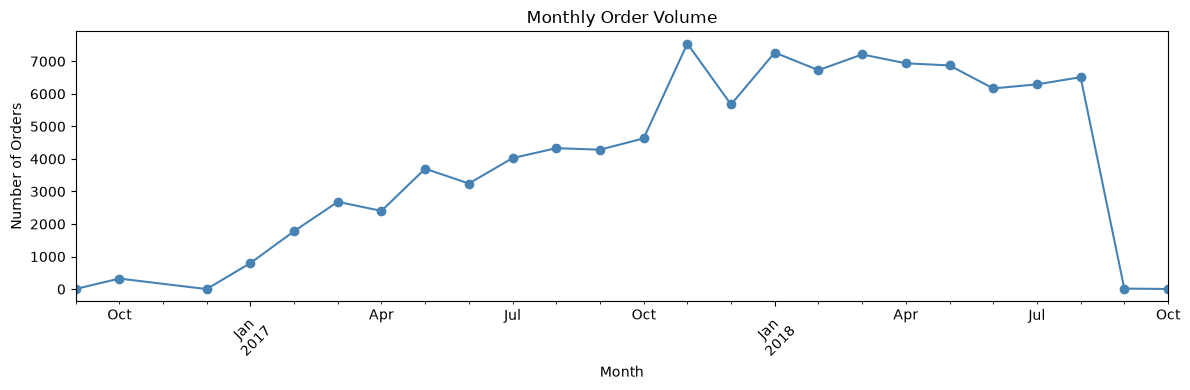

In [38]:
# Order volume over time
orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M')
monthly = orders.groupby('purchase_month').size()

fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(kind='line', ax=ax, marker='o', color='steelblue')
ax.set_title('Monthly Order Volume')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. EDA — Reviews

In [39]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


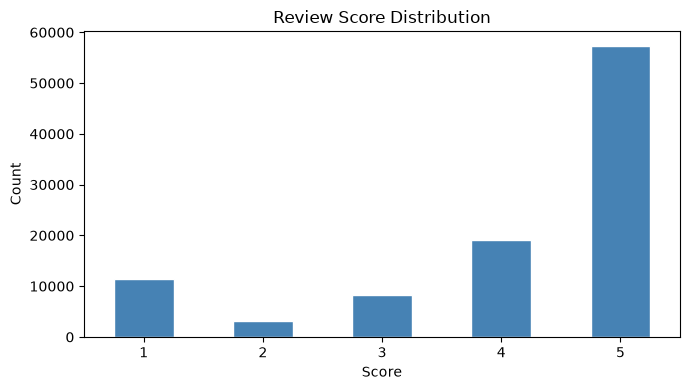

count   99224.00
mean        4.09
std         1.35
min         1.00
25%         4.00
50%         5.00
75%         5.00
max         5.00
Name: review_score, dtype: float64


In [40]:
# Score distribution
fig, ax = plt.subplots(figsize=(7, 4))
reviews['review_score'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Review Score Distribution')
ax.set_xlabel('Score')
ax.set_ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(reviews['review_score'].describe())

In [41]:
# How many reviews have free-text comments?
print(f"Reviews with comment title:   {reviews['review_comment_title'].notna().sum():,}")
print(f"Reviews with comment message: {reviews['review_comment_message'].notna().sum():,}")
print(f"Total reviews:                {len(reviews):,}")

Reviews with comment title:   11,568
Reviews with comment message: 40,977
Total reviews:                99,224


## 6. EDA — Products

In [42]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [43]:
# Category names are in Portuguese
pt_categories = set(products['product_category_name'].dropna().unique())
en_categories = set(translations['product_category_name'].unique())

untranslated = pt_categories - en_categories
print(f'Categories in products:    {len(pt_categories)}')
print(f'Categories in translation: {len(en_categories)}')
print(f'Untranslated categories:   {len(untranslated)}')
if untranslated:
    print('Missing:', untranslated)

Categories in products:    73
Categories in translation: 71
Untranslated categories:   2
Missing: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [44]:
# Product dimension/weight nulls
dim_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
print(products[dim_cols].isnull().sum())

product_weight_g     2
product_length_cm    2
product_height_cm    2
product_width_cm     2
dtype: int64


## 7. EDA — Payments

In [45]:
print(payments['payment_type'].value_counts())
print(f"\nPayment value stats:")
print(payments['payment_value'].describe())

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Payment value stats:
count   103886.00
mean       154.10
std        217.49
min          0.00
25%         56.79
50%        100.00
75%        171.84
max      13664.08
Name: payment_value, dtype: float64


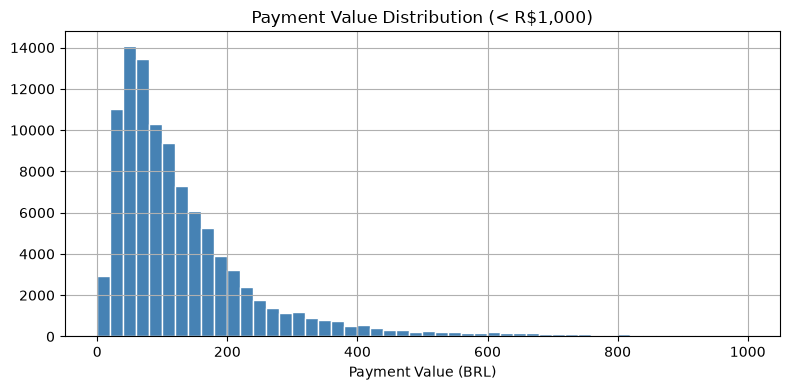

Orders with payment > R$1,000: 1150


In [46]:
# Outlier check — extreme payment values
fig, ax = plt.subplots(figsize=(8, 4))
payments[payments['payment_value'] < 1000]['payment_value'].hist(bins=50, ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Payment Value Distribution (< R$1,000)')
ax.set_xlabel('Payment Value (BRL)')
plt.tight_layout()
plt.show()

print(f"Orders with payment > R$1,000: {(payments['payment_value'] > 1000).sum()}")

## 8. EDA — Duplicates Check

In [47]:
for name, df in datasets.items():
    dupes = df.duplicated().sum()
    print(f'{name:15s}: {dupes} duplicate rows')

orders         : 0 duplicate rows
customers      : 0 duplicate rows
order_items    : 0 duplicate rows
payments       : 0 duplicate rows
reviews        : 0 duplicate rows
products       : 0 duplicate rows
sellers        : 0 duplicate rows
geolocation    : 261831 duplicate rows
translations   : 0 duplicate rows


In [48]:
# Geolocation has known duplicates (multiple lat/lng per zip)
geo_dupes = geolocation.duplicated(subset='geolocation_zip_code_prefix').sum()
print(f'Geolocation zip code duplicates: {geo_dupes:,}')
print(f'Unique zip codes: {geolocation["geolocation_zip_code_prefix"].nunique():,}')

Geolocation zip code duplicates: 981,148
Unique zip codes: 19,015


## 9. EDA Summary — Issues Found

| # | Table | Issue | Action |
|---|-------|-------|--------|
| 1 | orders | Date columns stored as string | Parse to datetime |
| 2 | orders | Nulls in approval/delivery dates | Keep — tied to cancelled/unavailable status |
| 3 | orders | Filter to delivered orders only for analysis | Drop non-delivered |
| 4 | reviews | ~58% missing comment text | OK — score is the key field |
| 5 | products | Category names in Portuguese | Join with translations table |
| 6 | products | ~600 rows missing dimensions/weight | Impute with category median |
| 7 | geolocation | Duplicate zip codes | Keep first occurrence per zip |
| 8 | payments | Zero-value payments exist | Investigate — may be voucher-only orders |

---
# Data Cleaning
Based on the EDA findings above, addressing each issue in order.

## 10. Clean — Orders

In [49]:
# Reload fresh (EDA already parsed dates above, but keeping it explicit)
orders_clean = pd.read_csv(DATA_PATH + 'olist_orders_dataset.csv')

# Parse all timestamp columns
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col], errors='coerce')

# Only keep delivered orders for satisfaction analysis
orders_clean = orders_clean[orders_clean['order_status'] == 'delivered'].copy()
print(f'Delivered orders: {len(orders_clean):,}')

# Derived columns
orders_clean['delivery_days'] = (
    orders_clean['order_delivered_customer_date'] - orders_clean['order_purchase_timestamp']
).dt.days

orders_clean['delay_days'] = (
    orders_clean['order_delivered_customer_date'] - orders_clean['order_estimated_delivery_date']
).dt.days  # negative = early, positive = late

orders_clean['purchase_year']  = orders_clean['order_purchase_timestamp'].dt.year
orders_clean['purchase_month'] = orders_clean['order_purchase_timestamp'].dt.month
orders_clean['purchase_quarter'] = orders_clean['order_purchase_timestamp'].dt.quarter

# Drop rows where delivery_days is negative or impossibly large (>180 days)
before = len(orders_clean)
orders_clean = orders_clean[(orders_clean['delivery_days'] >= 0) & (orders_clean['delivery_days'] <= 180)]
print(f'Dropped {before - len(orders_clean)} rows with invalid delivery days')
print(orders_clean['delivery_days'].describe())

Delivered orders: 96,478
Dropped 22 rows with invalid delivery days
count   96456.00
mean       12.07
std         9.30
min         0.00
25%         6.00
50%        10.00
75%        15.00
max       175.00
Name: delivery_days, dtype: float64


## 11. Clean — Products (translate + impute)

In [50]:
products_clean = products.merge(translations, on='product_category_name', how='left')

# For products with no translation, fill with original Portuguese name
products_clean['category_en'] = products_clean['product_category_name_english'].fillna(
    products_clean['product_category_name']
)

# Impute missing dimensions with category median
dim_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for col in dim_cols:
    products_clean[col] = products_clean.groupby('category_en')[col].transform(
        lambda x: x.fillna(x.median())
    )
    # Any remaining nulls (whole category missing) → overall median
    products_clean[col] = products_clean[col].fillna(products_clean[col].median())

print(f'Products cleaned: {len(products_clean):,}')
print(products_clean[dim_cols].isnull().sum())

Products cleaned: 32,951
product_weight_g     0
product_length_cm    0
product_height_cm    0
product_width_cm     0
dtype: int64


## 12. Clean — Reviews

In [51]:
reviews_clean = reviews[['review_id', 'order_id', 'review_score']].copy()

# Drop rows with no score (can't analyse without it)
reviews_clean = reviews_clean.dropna(subset=['review_score'])

# Binary satisfaction flag: 4-5 = satisfied
reviews_clean['satisfied'] = (reviews_clean['review_score'] >= 4).astype(int)

# Keep one review per order (take the most recent if duplicates exist)
reviews_clean = reviews_clean.drop_duplicates(subset='order_id', keep='last')

print(f'Reviews cleaned: {len(reviews_clean):,}')
print(f"Satisfaction rate: {reviews_clean['satisfied'].mean()*100:.1f}%")

Reviews cleaned: 98,673
Satisfaction rate: 77.1%


## 13. Clean — Geolocation

In [52]:
# Keep first lat/lng per zip code
geo_clean = geolocation.drop_duplicates(subset='geolocation_zip_code_prefix', keep='first')
geo_clean = geo_clean[['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']]
print(f'Geo records after dedup: {len(geo_clean):,}')

Geo records after dedup: 19,015


## 14. Build Master Analytical Table

In [53]:
# Aggregate payments per order (sum values, keep payment type of highest value)
pay_agg = payments.groupby('order_id').agg(
    total_payment=('payment_value', 'sum'),
    payment_installments=('payment_installments', 'max')
).reset_index()

# Aggregate items per order
items_agg = order_items.groupby('order_id').agg(
    item_count=('order_item_id', 'count'),
    total_freight=('freight_value', 'sum')
).reset_index()

# Join everything
master = (
    orders_clean
    .merge(customers, on='customer_id', how='left')
    .merge(reviews_clean[['order_id', 'review_score', 'satisfied']], on='order_id', how='left')
    .merge(pay_agg, on='order_id', how='left')
    .merge(items_agg, on='order_id', how='left')
)

print(f'Master table shape: {master.shape}')
master.head(3)

Master table shape: (96456, 23)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,purchase_year,purchase_month,purchase_quarter,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score,satisfied,total_payment,payment_installments,item_count,total_freight
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.00,-8.00,2017,10,4,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.00,1.00,38.71,1.00,1,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.00,-6.00,2018,7,3,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.00,1.00,141.46,1.00,1,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.00,-18.00,2018,8,3,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.00,1.00,179.12,3.00,1,19.22


## 15. Export Clean Data

In [54]:
CLEAN_PATH = 'da_ecommerce/data/clean/'
os.makedirs(CLEAN_PATH, exist_ok=True)

orders_clean.to_csv(CLEAN_PATH + 'orders_clean.csv', index=False)
products_clean.to_csv(CLEAN_PATH + 'products_clean.csv', index=False)
reviews_clean.to_csv(CLEAN_PATH + 'reviews_clean.csv', index=False)
geo_clean.to_csv(CLEAN_PATH + 'geolocation_clean.csv', index=False)
master.to_csv(CLEAN_PATH + 'master.csv', index=False)
customers.to_csv(CLEAN_PATH + 'customers_clean.csv', index=False)
sellers.to_csv(CLEAN_PATH + 'sellers_clean.csv', index=False)
order_items.to_csv(CLEAN_PATH + 'order_items_clean.csv', index=False)
pay_agg.to_csv(CLEAN_PATH + 'payments_clean.csv', index=False)

print('All clean files saved to', CLEAN_PATH)

All clean files saved to da_ecommerce/data/clean/
